# SC4000: Opponent-adjusted NCAA probability forecasting

## tl;dr

This notebook implements, trains, evaluates and exports a probability model for the NCAA tournaments (Kaggle March Machine Learning Mania 2026). All model code is in the cells; only the supplied CSV files and standard scientific Python libraries are required.

The selected model obtains **0.16303 Brier** on 1,315 tournament games across 2015–2025, against 0.16644 for the previous version of this model on the same games (the earlier figure comes from the earlier experiment and is not recomputed here). On the 402 games from 2023–2025 it obtains **0.15832**. Every score is out-of-sample: the settings for each season are chosen from earlier seasons only.

Two caveats matter. Box scores were dropped from the main model after the earlier version had been scored on 2023–2025, so those seasons are not fully untouched. And no public Kaggle score is claimed.

## Context & Methods

The task is to predict the probability that the lower-ID team beats the higher-ID team in each tournament game. Men and women have separate models. Both combine full-season and recent opponent-adjusted margin ratings, Elo carried across seasons, schedule strength, win percentage, margin and seeds; the men's model adds a consensus computer ranking.

### Key Assumptions

- **Information cut-off.** Features use regular-season games through DayNum 132, rankings published by DayNum 133, and seeds known before the tournament. No 2026 tournament outcomes are present.
- **Training history.** Training starts in the first tournament season in which every feature exists: 2003 for men (when the rankings begin) and 1998 for women.
- **Evaluation.** Nested rolling-origin over 2015–2019 and 2021–2025. Each season selects its settings on the five preceding tournament seasons and is fitted on strictly earlier seasons, so no later season informs an earlier prediction. Stage 1 seasons 2022–2025 follow the same select-then-fit procedure.
- **Scoring.** Mirrored rows are training augmentation only and are never counted twice in a score.

### 1. Libraries and configuration

Python 3.12 was used with NumPy 2.4.6, pandas 3.0.3, SciPy 1.15.3, scikit-learn 1.8.0, matplotlib 3.10.9 and joblib 1.5.3. Set the data directory below if auto-discovery fails. No local Python module, previous notebook, saved model or prior result file is needed to run this notebook.

In [1]:
import os
os.environ.setdefault('OMP_NUM_THREADS', '2')
os.environ.setdefault('OPENBLAS_NUM_THREADS', '2')
from pathlib import Path
import json, platform, time
import numpy as np
import pandas as pd
from scipy.sparse import coo_matrix, eye, vstack
from scipy.sparse.linalg import lsqr
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import brier_score_loss, log_loss, roc_auc_score
import sklearn, scipy, joblib
import matplotlib.pyplot as plt
from IPython.display import display

# All implementation code is in this notebook. Set DATA_DIR here if auto-discovery fails.
ROOT = Path.cwd()
configured_data = os.environ.get('SC4000_DATA_DIR')
data_candidates = ([Path(configured_data)] if configured_data else []) + [ROOT/'Data', ROOT.parent/'Data', ROOT/'SC4000'/'Project_WORK'/'Data']
if Path('/kaggle/input').exists():
    data_candidates += [p.parent for p in Path('/kaggle/input').rglob('MTeams.csv')]
DATA_DIR = next((p.resolve() for p in data_candidates if (p/'MTeams.csv').is_file()), None)
if DATA_DIR is None:
    raise FileNotFoundError('Set DATA_DIR or SC4000_DATA_DIR to the supplied CSV directory.')
RESULTS = Path(os.environ.get('SC4000_OUTPUT_DIR', ROOT/'results'/'independent')).resolve()
RESULTS.mkdir(parents=True, exist_ok=True)
EVAL = [2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025]
INNER = 5
C_GRID = [.001, .01, .1, 1., 10.]
TREE_WEIGHTS = [0., .25, .5, .75, 1.]
ELO_CARRY = .75
STRENGTH = ['SRS', 'RecentSRS', 'Elo', 'SOS']
BOX = ['OffEff', 'DefEff', 'EFG', 'OppEFG', 'TORate', 'OppTORate', 'ORRate', 'FTRate']
CORE = ['Seed', 'WinPct', 'Margin'] + STRENGTH

def feature_sets(gender):
    """Men add the consensus computer ranking; women have no ranking data."""
    full = CORE + (['Rank'] if gender == 'M' else [])
    return {'full': full, 'no_strength': [f for f in full if f not in STRENGTH],
            'no_seed': [f for f in full if f != 'Seed'], 'no_recency': [f for f in full if f != 'RecentSRS'],
            'no_rank': [f for f in full if f != 'Rank'], 'plus_box': full + BOX}
BLUE, GOLD = '#285f8f', '#b07818'
plt.rcParams.update({'font.size': 11, 'axes.spines.top': False, 'axes.spines.right': False,
                     'figure.facecolor': 'white', 'savefig.facecolor': 'white'})
print('Data:', DATA_DIR)
print('Outputs:', RESULTS)
print('Evaluation seasons:', EVAL, '| inner folds per season:', INNER)

Data: C:\Users\Lenovo\Desktop\Study\SC4000\Project_WORK\fresh_experiment\Data
Outputs: C:\Users\Lenovo\Desktop\Study\SC4000\Project_WORK\fresh_experiment\results\independent
Evaluation seasons: [2015, 2016, 2017, 2018, 2019, 2021, 2022, 2023, 2024, 2025] | inner folds per season: 5


## Data

### 2. Inspect the model inputs

The inputs are team identifiers, regular-season compact and detailed results, the men's pre-tournament computer rankings (Massey ordinals), tournament seeds, tournament results (the targets) and the sample submission IDs. Tournament detailed results are excluded from the predictors. Every summary below is calculated directly from the supplied files.

In [2]:
def load(data_dir, name):
    return pd.read_csv(Path(data_dir) / (name + '.csv'))

data_summary = []
for gender in ['M', 'W']:
    for suffix in ['Teams', 'RegularSeasonCompactResults', 'RegularSeasonDetailedResults', 'NCAATourneySeeds', 'NCAATourneyCompactResults'] + (['MasseyOrdinals'] if gender == 'M' else []):
        table = load(DATA_DIR, gender+suffix)
        data_summary.append({'Table': gender+suffix, 'Rows': len(table), 'Missing cells': int(table.isna().sum().sum()),
                             'First season': table.Season.min() if 'Season' in table else None,
                             'Last season': table.Season.max() if 'Season' in table else None})
display(pd.DataFrame(data_summary))

,Table,Rows,Missing cells,First season,Last season
0,MTeams,381,0,NaN,NaN
1,MRegularSeasonCompactResults,198577,0,1985.0,2026.0
2,MRegularSeasonDetailedResults,124529,0,2003.0,2026.0
3,MNCAATourneySeeds,2694,0,1985.0,2026.0
4,MNCAATourneyCompactResults,2585,0,1985.0,2025.0
5,MMasseyOrdinals,5865001,0,2003.0,2026.0
6,WTeams,379,0,NaN,NaN
7,WRegularSeasonCompactResults,142507,0,1998.0,2026.0
8,WRegularSeasonDetailedResults,87187,0,2010.0,2026.0
9,WNCAATourneySeeds,1812,0,1998.0,2026.0


### 3. Estimate opponent-adjusted strength

For each season, ratings come from a ridge least-squares fit to home-adjusted margins: minimise $\sum_g w_g(m_g-r_i+r_j)^2+10\sum_i r_i^2$. Each margin is capped at 30 points after subtracting a fixed three-point home correction. Full-season weights equal one; recent-form weights use a 30-day half-life relative to the last observed game. Ratings are centred at zero. These are fixed assumptions rather than constants tuned on the evaluation seasons.

In [3]:
def adjusted_ratings(games, teams, half_life=None):
    """Ridge least squares of home-adjusted capped margins; ratings sum to zero."""
    lookup = {t: i for i, t in enumerate(teams)}
    n, m = len(teams), len(games)
    rows = np.repeat(np.arange(m), 2)
    cols = np.column_stack([games.WTeamID.map(lookup), games.LTeamID.map(lookup)]).ravel()
    loc = games.WLoc.map({'H': 1., 'A': -1., 'N': 0.}).to_numpy()
    margin = np.clip(games.WScore.to_numpy() - games.LScore.to_numpy() - 3 * loc, -30, 30)
    w = np.ones(m) if half_life is None else 2. ** (-(games.DayNum.max() - games.DayNum.to_numpy()) / half_life)
    a = coo_matrix((np.column_stack([np.sqrt(w), -np.sqrt(w)]).ravel(), (rows, cols)), shape=(m, n)).tocsr()
    a = vstack([a, np.sqrt(10.) * eye(n)])
    ratings = lsqr(a, np.r_[margin * np.sqrt(w), np.zeros(n)], atol=1e-9, btol=1e-9)[0]
    return dict(zip(teams, ratings - ratings.mean()))

### 4. Build team-season features

- **Elo.** Each season starts at 75% of the team's previous-season rating plus 25% of 1500 (new teams start at 1500), with K=24 and a 100-point home adjustment. Games are processed in deterministic day/ID order.
- **Schedule strength.** The mean full-season rating of a team's opponents.
- **Men's ranking.** The median, across ranking systems, of each system's last ordinal published by DayNum 133, transformed as −log(rank). Women have no equivalent data.
- **Box-score rates (ablation only).** Offensive and defensive points per 100 estimated possessions, effective shooting percentages, turnover rates, offensive rebound rate and free-throw attempt rate, from aggregated own and opponent totals. Possessions are FGA−OR+TO+0.475×FTA averaged across both sides. These rates are not opponent-adjusted, and they appear only in the with-box-scores variant.

In [4]:
def season_features(compact, detailed, seeds, ordinals=None):
    parts, elo_prev = [], {}
    ranks = {} if ordinals is None else dict(tuple(ordinals[ordinals.RankingDayNum <= 133].groupby('Season')))
    for season, g in compact.groupby('Season', sort=True):
        g = g.sort_values(['DayNum', 'WTeamID', 'LTeamID'])
        assert g.DayNum.max() <= 132
        teams = np.union1d(g.WTeamID, g.LTeamID)
        srs, recent = adjusted_ratings(g, teams), adjusted_ratings(g, teams, 30.)
        elo = {t: ELO_CARRY*elo_prev.get(t, 1500.) + (1-ELO_CARRY)*1500. for t in teams}
        for row in g.itertuples(index=False):
            h = {'H': 100., 'A': -100., 'N': 0.}[row.WLoc]
            expected = 1. / (1. + 10. ** ((elo[row.LTeamID] - elo[row.WTeamID] - h) / 400.))
            delta = 24. * (1. - expected)
            elo[row.WTeamID] += delta
            elo[row.LTeamID] -= delta
        elo_prev.update(elo)
        long = pd.concat([
            pd.DataFrame({'TeamID': g.WTeamID, 'Opponent': g.LTeamID, 'Win': 1., 'Margin': g.WScore-g.LScore}),
            pd.DataFrame({'TeamID': g.LTeamID, 'Opponent': g.WTeamID, 'Win': 0., 'Margin': g.LScore-g.WScore})])
        long['OppSRS'] = long.Opponent.map(srs)
        f = long.groupby('TeamID').agg(WinPct=('Win','mean'), Margin=('Margin','mean'), SOS=('OppSRS','mean'), Games=('Win','size'))
        f['SRS'], f['RecentSRS'], f['Elo'] = pd.Series(srs), pd.Series(recent), pd.Series(elo)
        if season in ranks:
            latest = ranks[season].sort_values('RankingDayNum').groupby(['SystemName', 'TeamID']).OrdinalRank.last()
            f['Rank'] = -np.log(latest.groupby('TeamID').median())
        else:
            f['Rank'] = np.nan
        d = detailed[detailed.Season == season]
        if not d.empty:
            sides = []
            for side, opp in [('W', 'L'), ('L', 'W')]:
                q = pd.DataFrame({'TeamID': d[side+'TeamID'], 'Score': d[side+'Score'], 'OppScore': d[opp+'Score']})
                for col in ['FGM', 'FGA', 'FGM3', 'FTA', 'OR', 'DR', 'TO']:
                    q[col], q['Opp'+col] = d[side+col], d[opp+col]
                sides.append(q)
            q = pd.concat(sides).groupby('TeamID').sum()
            poss = .5 * ((q.FGA-q.OR+q.TO+.475*q.FTA) + (q.OppFGA-q.OppOR+q.OppTO+.475*q.OppFTA))
            b = pd.DataFrame(index=q.index)
            b['OffEff'], b['DefEff'] = 100*q.Score/poss, 100*q.OppScore/poss
            b['EFG'], b['OppEFG'] = (q.FGM+.5*q.FGM3)/q.FGA, (q.OppFGM+.5*q.OppFGM3)/q.OppFGA
            b['TORate'], b['OppTORate'] = q.TO/poss, q.OppTO/poss
            b['ORRate'], b['FTRate'] = q.OR/(q.OR+q.OppDR), q.FTA/q.FGA
            f = f.join(b, validate='one_to_one')
        for col in BOX:
            if col not in f:
                f[col] = np.nan
        sd = seeds[seeds.Season == season].set_index('TeamID').Seed.str[1:3].astype(int)
        f['Seed'] = sd
        f['Season'] = season
        parts.append(f.reset_index())
    return pd.concat(parts, ignore_index=True)

### 5. Construct canonical matchups and validate coverage

Each target game has one row, with the lower-ID team first. Matchup features are Team1 statistics minus Team2 statistics. Validation checks identifiers, scores, locations, game keys and seed syntax. Training uses only seasons in which every model feature exists, and a missing feature in a scored game raises an error rather than being filled silently.

In [5]:
def matchups(features, games):
    """Canonical orientation: lower ID team is Team1; score only one row per game."""
    p = pd.DataFrame({'Season': games.Season, 'Team1': np.minimum(games.WTeamID, games.LTeamID),
                      'Team2': np.maximum(games.WTeamID, games.LTeamID), 'DayNum': games.DayNum})
    p['Target'] = (p.Team1 == games.WTeamID).astype(int)
    p['ID'] = p.Season.astype(str)+'_'+p.Team1.astype(str)+'_'+p.Team2.astype(str)
    return p.reset_index(drop=True)

def differences(features, pairs, columns):
    f = features.set_index(['Season', 'TeamID'])
    out = []
    for team in ['Team1', 'Team2']:
        keys = pd.MultiIndex.from_arrays([pairs.Season, pairs[team]], names=['Season','TeamID'])
        out.append(f.reindex(keys)[columns].to_numpy(float))
    return out[0] - out[1]

def prepare(data_dir):
    datasets = {}
    for gender in ['M','W']:
        compact = load(data_dir, gender+'RegularSeasonCompactResults')
        detailed = load(data_dir, gender+'RegularSeasonDetailedResults')
        seeds = load(data_dir, gender+'NCAATourneySeeds')
        teams = load(data_dir, gender+'Teams')
        tournament = load(data_dir, gender+'NCAATourneyCompactResults')
        ordinals = load(data_dir, 'MMasseyOrdinals') if gender == 'M' else None
        for g in [compact, detailed, tournament]:
            assert not g.duplicated(['Season','DayNum','WTeamID','LTeamID']).any()
            assert g.WLoc.isin(['H','A','N']).all() and (g.WScore > g.LScore).all()
            assert g.WTeamID.isin(teams.TeamID).all() and g.LTeamID.isin(teams.TeamID).all()
        assert not seeds.duplicated(['Season','TeamID']).any()
        assert seeds.Seed.str.fullmatch(r'[A-Z]\d{2}[a-z]?').all()
        f = season_features(compact[compact.DayNum <= 132], detailed[detailed.DayNum <= 132], seeds, ordinals)
        pairs = matchups(f, tournament)
        datasets[gender] = {'features': f, 'games': pairs, 'regular': compact}
        f.to_csv(RESULTS / f'{gender}_team_features.csv', index=False)
        print(gender, 'features', f.shape, 'tournament games', len(pairs), flush=True)
    return datasets

datasets = prepare(DATA_DIR)
for gender in datasets:
    print(gender, 'feature columns:', feature_sets(gender)['full'])

M features (13753, 19) tournament games 2585


W features (9851, 19) tournament games 1717


M feature columns: ['Seed', 'WinPct', 'Margin', 'SRS', 'RecentSRS', 'Elo', 'SOS', 'Rank']
W feature columns: ['Seed', 'WinPct', 'Margin', 'SRS', 'RecentSRS', 'Elo', 'SOS']


### 6. Define probability models

The main model is a regularised logistic regression behind a scaler fitted on the training data; a fixed, shallow histogram-boosted tree model is the alternative. Training augmentation adds each row's mirror (−x, 1−y), and predictions are symmetrised so that p(x)+p(−x)=1. Probabilities are clipped to [10⁻⁶, 1−10⁻⁶]. Brier score is the primary metric; log loss, accuracy and AUC are supplementary.

In [6]:
def fit_model(x, y, kind='lr', c=1.):
    if not np.isfinite(x).all():
        raise ValueError('Missing feature; inspect coverage instead of silently filling it.')
    xx, yy = np.r_[x, -x], np.r_[y, 1-y]
    model = (make_pipeline(StandardScaler(), LogisticRegression(C=c, max_iter=2000, random_state=42)) if kind == 'lr'
             else HistGradientBoostingClassifier(max_iter=150, learning_rate=.05, max_leaf_nodes=7,
                 min_samples_leaf=40, l2_regularization=5., early_stopping=False, random_state=42))
    model.fit(xx, yy)
    return model

def design(features, pairs, columns):
    """Training matrix from games whose seasons have every requested feature."""
    x = differences(features, pairs, columns)
    keep = np.isfinite(x).all(axis=1)
    return x[keep], pairs.Target.to_numpy()[keep]

def predict(model, x):
    return np.clip(.5*(model.predict_proba(x)[:,1] + 1-model.predict_proba(-x)[:,1]), 1e-6, 1-1e-6)

def metrics(y, p):
    return {'Games': len(y), 'Brier': float(brier_score_loss(y,p)), 'LogLoss': float(log_loss(y,p)),
            'Accuracy': float(np.mean((p >= .5) == y)), 'AUC': float(roc_auc_score(y,p))}

### 7. Select settings and run temporal evaluation

For each evaluation season, the five preceding tournament seasons serve as inner validation folds, each fitted on strictly earlier seasons. These folds select C∈{0.001, 0.01, 0.1, 1, 10} first and then the tree blend weight from {0, 0.25, 0.5, 0.75, 1}; the chosen settings are refitted on all earlier seasons, and the evaluation season is scored once.

Alongside the selected model, the evaluation includes a constant and a seed-only reference, controlled component removals, and a variant that re-adds box scores. Ablations keep each season's selected settings, so only the feature change differs. A paired game-level bootstrap compares every variant with the selected model on exactly the same games.

In [7]:
def select_settings(features, games, season, columns):
    """Choose C, then tree weight, on the INNER tournament seasons before `season`."""
    folds = sorted(games.Season[games.Season < season].unique())[-INNER:]
    logistic_oof = {c: [] for c in C_GRID}
    tree_oof, targets = [], []
    for fold in folds:
        x, y = design(features, games[games.Season < fold], columns)
        v, t = design(features, games[games.Season == fold], columns)
        for c in C_GRID:
            logistic_oof[c].extend(predict(fit_model(x, y, c=c), v))
        tree_oof.extend(predict(fit_model(x, y, kind='hgb'), v))
        targets.extend(t)
    targets = np.array(targets)
    best_c = min(C_GRID, key=lambda c: brier_score_loss(targets, logistic_oof[c]))
    logistic_pred, tree_pred = np.array(logistic_oof[best_c]), np.array(tree_oof)
    blend = lambda w: brier_score_loss(targets, (1-w)*logistic_pred + w*tree_pred)
    weight = min(TREE_WEIGHTS, key=blend)
    rows = ([{'C': c, 'TreeWeight': 0., 'Brier': brier_score_loss(targets, logistic_oof[c])} for c in C_GRID] +
            [{'C': best_c, 'TreeWeight': w, 'Brier': blend(w)} for w in TREE_WEIGHTS])
    settings = {'C': best_c, 'TreeWeight': weight, 'InnerBrier': float(blend(weight)),
                'InnerGames': len(targets), 'InnerFolds': [int(f) for f in folds]}
    return settings, rows

def fit_predict(features, train, valid, columns, settings):
    """Fit selected settings on complete-feature training games; predict `valid`."""
    x, y = design(features, train, columns)
    v = differences(features, valid, columns)
    lr = fit_model(x, y, c=settings['C'])
    tree = fit_model(x, y, kind='hgb') if settings['TreeWeight'] else None
    p = predict(lr, v)
    if tree is not None:
        p = (1-settings['TreeWeight'])*p + settings['TreeWeight']*predict(tree, v)
    return p, lr, tree

def evaluate_rolling(datasets):
    """Each evaluation season: select on earlier seasons, fit on all earlier seasons, score once."""
    predictions, selections, tuning_rows = [], [], []
    for gender, data in datasets.items():
        features, games = data['features'], data['games']
        sets = feature_sets(gender)
        for season in EVAL:
            train, valid = games[games.Season < season], games[games.Season == season]
            settings, rows = select_settings(features, games, season, sets['full'])
            selections.append({'Gender': gender, 'Season': season, **settings})
            tuning_rows += [{'Gender': gender, 'Season': season, **row} for row in rows]
            estimates = {'constant': np.full(len(valid), .5)}
            estimates['seed_only'] = fit_predict(features, train, valid, ['Seed'], {'C': 1., 'TreeWeight': 0.})[0]
            for name, columns in sets.items():
                estimates['proposed' if name == 'full' else name] = fit_predict(features, train, valid, columns, settings)[0]
            estimates['lr_only'] = fit_predict(features, train, valid, sets['full'], {**settings, 'TreeWeight': 0.})[0]
            estimates['tree_only'] = fit_predict(features, train, valid, sets['full'], {**settings, 'TreeWeight': 1.})[0]
            for name, probabilities in estimates.items():
                for row, probability in zip(valid.itertuples(index=False), probabilities):
                    predictions.append({'Gender': gender, 'Season': season, 'ID': row.ID,
                                        'Target': row.Target, 'Model': name, 'Pred': float(probability)})
            print('Evaluation', gender, season, 'C', settings['C'], 'tree', settings['TreeWeight'],
                  {k: round(v, 4) for k, v in metrics(valid.Target, estimates['proposed']).items()}, flush=True)
    game_predictions = pd.DataFrame(predictions)
    game_predictions.to_csv(RESULTS/'test_predictions.csv', index=False)
    pd.DataFrame(tuning_rows).to_csv(RESULTS/'development_search.csv', index=False)
    (RESULTS/'selected_settings.json').write_text(json.dumps(selections, indent=2))
    per_season = [{'Gender': gender, 'Season': year, 'Model': model, **metrics(g.Target, g.Pred)}
                  for (gender, year, model), g in game_predictions.groupby(['Gender', 'Season', 'Model'])]
    pd.DataFrame(per_season).to_csv(RESULTS/'season_metrics.csv', index=False)
    summary = []
    for model, group in game_predictions.groupby('Model'):
        summary.append({'Gender': 'Combined', 'Model': model, **metrics(group.Target, group.Pred)})
        for gender, g in group.groupby('Gender'):
            summary.append({'Gender': gender, 'Model': model, **metrics(g.Target, g.Pred)})
    pd.DataFrame(summary).to_csv(RESULTS/'pooled_metrics.csv', index=False)
    # Paired game-level bootstrap: every variant is scored on exactly the same games as the selected model.
    wide = game_predictions.pivot_table(index=['Gender', 'Season', 'ID', 'Target'], columns='Model', values='Pred').reset_index()
    loss = {m: ((wide[m]-wide.Target)**2).to_numpy() for m in game_predictions.Model.unique()}
    draws = np.random.default_rng(42).integers(0, len(wide), (5000, len(wide)))
    paired = []
    for model in sorted(loss):
        if model == 'proposed': continue
        delta = loss[model] - loss['proposed']
        boot = delta[draws].mean(axis=1)
        paired.append({'Model': model, 'Games': len(delta), 'DeltaBrier': float(delta.mean()),
                       'CI2.5': float(np.quantile(boot, .025)), 'CI97.5': float(np.quantile(boot, .975)),
                       'ShareVariantBetter': float((boot < 0).mean())})
    pd.DataFrame(paired).to_csv(RESULTS/'paired_differences.csv', index=False)
    boot = loss['proposed'][draws].mean(axis=1)
    uncertainty = {'Brier': float(loss['proposed'].mean()), 'GameBootstrap95Percentile': np.quantile(boot, [.025, .975]).tolist(),
                   'Games': len(wide), 'Replicates': 5000}
    (RESULTS/'uncertainty.json').write_text(json.dumps(uncertainty, indent=2))
    return selections, game_predictions, pd.DataFrame(summary), pd.DataFrame(per_season)


started = time.time()
selections, game_predictions, scores, season_scores = evaluate_rolling(datasets)
display(pd.DataFrame(selections).drop(columns='InnerFolds').round(5))


Evaluation M 2015 C 0.01 tree 0.25 {'Games': 67, 'Brier': 0.1712, 'LogLoss': 0.5145, 'Accuracy': 0.7761, 'AUC': 0.8306}


Evaluation M 2016 C 0.01 tree 0.25 {'Games': 67, 'Brier': 0.1808, 'LogLoss': 0.5434, 'Accuracy': 0.7463, 'AUC': 0.7985}


Evaluation M 2017 C 0.01 tree 0.25 {'Games': 67, 'Brier': 0.1717, 'LogLoss': 0.5052, 'Accuracy': 0.7015, 'AUC': 0.844}


Evaluation M 2018 C 10.0 tree 0.5 {'Games': 67, 'Brier': 0.2002, 'LogLoss': 0.5953, 'Accuracy': 0.6716, 'AUC': 0.7545}


Evaluation M 2019 C 10.0 tree 0.25 {'Games': 67, 'Brier': 0.1596, 'LogLoss': 0.4707, 'Accuracy': 0.7015, 'AUC': 0.8475}


...

Evaluation W 2022 C 0.1 tree 0.0 {'Games': 67, 'Brier': 0.1504, 'LogLoss': 0.4524, 'Accuracy': 0.7612, 'AUC': 0.8599}


Evaluation W 2023 C 0.1 tree 0.0 {'Games': 67, 'Brier': 0.1716, 'LogLoss': 0.5051, 'Accuracy': 0.7612, 'AUC': 0.8221}


Evaluation W 2024 C 0.01 tree 0.0 {'Games': 67, 'Brier': 0.1214, 'LogLoss': 0.3827, 'Accuracy': 0.8358, 'AUC': 0.9259}


Evaluation W 2025 C 0.1 tree 0.0 {'Games': 67, 'Brier': 0.1049, 'LogLoss': 0.335, 'Accuracy': 0.8358, 'AUC': 0.9405}


,Gender,Season,C,TreeWeight,InnerBrier,InnerGames
0,M,2015,0.01,0.25,0.20063,332
1,M,2016,0.01,0.25,0.19751,335
2,M,2017,0.01,0.25,0.18991,335
3,M,2018,10.00,0.50,0.18558,335
4,M,2019,10.00,0.25,0.18345,335
5,M,2021,10.00,0.50,0.17472,335
6,M,2022,10.00,0.75,0.18143,334
7,M,2023,10.00,0.75,0.19139,334
8,M,2024,0.01,0.50,0.20111,334
9,M,2025,0.01,0.50,0.19917,334


## Results

### 8. Inspect internal baselines and ablations

,Gender,Model,Games,Brier,LogLoss,Accuracy,AUC
0,Combined,no_rank,1315,0.16237,0.48493,0.74981,0.84104
1,Combined,proposed,1315,0.16303,0.48632,0.74449,0.83985
2,Combined,no_recency,1315,0.16306,0.48625,0.74829,0.83975
3,Combined,lr_only,1315,0.16316,0.48717,0.74677,0.83975
4,Combined,no_seed,1315,0.16395,0.48861,0.74601,0.83809
5,Combined,plus_box,1315,0.16478,0.49154,0.76046,0.83749
6,Combined,tree_only,1315,0.16592,0.49430,0.74905,0.83479
7,Combined,no_strength,1315,0.16774,0.49994,0.75361,0.83133
8,Combined,seed_only,1315,0.17310,0.51320,0.73916,0.81886
9,Combined,constant,1315,0.25000,0.69315,0.49582,0.50000


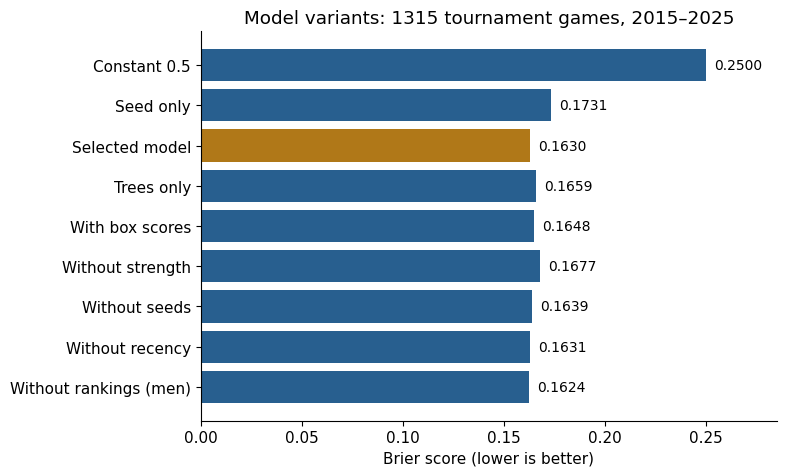

In [8]:
combined = scores[scores.Gender == 'Combined'].sort_values('Brier')
display(combined.reset_index(drop=True).round(5))
plot_order = ['constant', 'seed_only', 'proposed', 'tree_only', 'plus_box', 'no_strength', 'no_seed', 'no_recency', 'no_rank']
labels = ['Constant 0.5', 'Seed only', 'Selected model', 'Trees only', 'With box scores', 'Without strength', 'Without seeds', 'Without recency', 'Without rankings (men)']
values = combined.set_index('Model').loc[plot_order, 'Brier']
fig, ax = plt.subplots(figsize=(8, 4.9))
ax.barh(labels, values, color=[GOLD if name == 'proposed' else BLUE for name in plot_order])
for i, value in enumerate(values): ax.text(value+.004, i, f'{value:.4f}', va='center', fontsize=10)
ax.set(xlim=(0,.285), xlabel='Brier score (lower is better)', title=f'Model variants: {int(combined.Games.max())} tournament games, {EVAL[0]}–{EVAL[-1]}')
ax.invert_yaxis(); fig.tight_layout()
fig.savefig(RESULTS/'model_variants.png', dpi=180)
plt.show()

Selected settings vary by season. Men use C=0.01 or C=10 with tree weights of 0.25–0.75, whereas women mostly use C=0.1 with no trees. The selected model obtains Brier 0.16303 and log loss 0.48632.

- **Against seeds alone:** the model is better by 0.0101 (paired 95% interval 0.0053–0.0149).
- **Strength ratings:** removing them costs 0.0047 (0.0019–0.0075), so opponent-adjusted strength is the component with demonstrated value.
- **Box scores:** re-adding them is worse by 0.0017, with an interval that includes zero, so they are not shown to help.
- **Men's rankings:** removing them scores 0.0007 *better*, again with an interval that includes zero, so the rankings are not shown to help either.
- **Recent form:** removing it has almost no effect.

These are diagnostic results from a single pass over the evaluation seasons. They motivate a confirmation experiment on new data; they are not an independently confirmed improvement.

### 9. Examine season variation and reliability

,Gender,Season,Model,Games,Brier,LogLoss,Accuracy,AUC
0,M,2015,proposed,67,0.17117,0.51452,0.77612,0.83065
1,M,2016,proposed,67,0.18079,0.54337,0.74627,0.79855
2,M,2017,proposed,67,0.17167,0.50518,0.70149,0.84403
3,M,2018,proposed,67,0.20021,0.59531,0.67164,0.75448
4,M,2019,proposed,67,0.15963,0.47068,0.70149,0.84755
5,M,2021,proposed,66,0.20952,0.59977,0.66667,0.75000
6,M,2022,proposed,67,0.22705,0.66155,0.62687,0.71250
7,M,2023,proposed,67,0.21732,0.62872,0.61194,0.70556
8,M,2024,proposed,67,0.19034,0.55499,0.68657,0.74031
9,M,2025,proposed,67,0.14437,0.44712,0.79104,0.89194


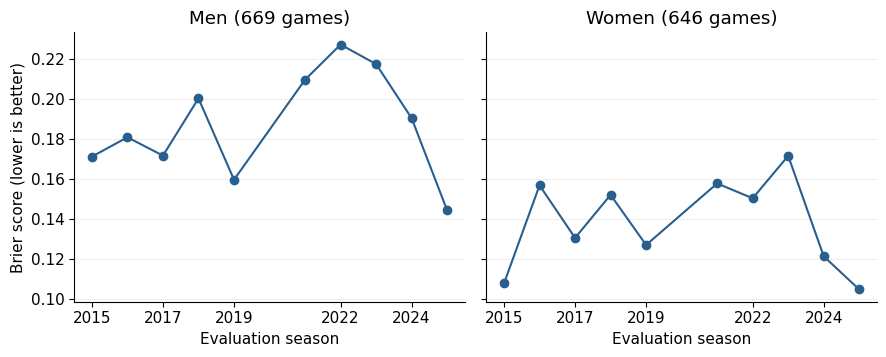

,Bin,Probability,Frequency,Games
0,0,0.0878,0.0681,279
1,1,0.3075,0.3156,225
2,2,0.5028,0.5036,278
3,3,0.6947,0.6733,251
4,4,0.9077,0.8972,282


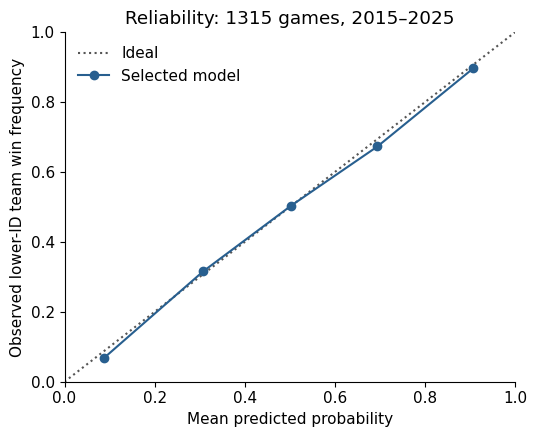

,Model,Games,DeltaBrier,CI2.5,CI97.5,ShareVariantBetter
0,constant,1315,0.08697,0.07622,0.09729,0.0000
1,lr_only,1315,0.00013,-0.00132,0.00154,0.4432
2,no_rank,1315,-0.00066,-0.00177,0.00036,0.8902
3,no_recency,1315,0.00003,-0.00040,0.00045,0.4408
4,no_seed,1315,0.00091,-0.00011,0.00190,0.0428
5,no_strength,1315,0.00471,0.00193,0.00752,0.0008
6,plus_box,1315,0.00174,-0.00056,0.00411,0.0674
7,seed_only,1315,0.01006,0.00531,0.01486,0.0000
8,tree_only,1315,0.00288,0.00074,0.00504,0.0052


{
  "Brier": 0.16303382235385475,
  "GameBootstrap95Percentile": [
    0.15270966093494262,
    0.17378212674713073
  ],
  "Games": 1315,
  "Replicates": 5000
}


In [9]:
display(season_scores[season_scores.Model == 'proposed'].reset_index(drop=True).round(5))
fig, axes = plt.subplots(1, 2, figsize=(9, 3.7), sharey=True)
for ax, gender, title in zip(axes, ['M', 'W'], ['Men', 'Women']):
    frame = season_scores[(season_scores.Gender == gender) & (season_scores.Model == 'proposed')]
    ax.plot(frame.Season, frame.Brier, color=BLUE, marker='o')
    ax.set(title=f'{title} ({frame.Games.sum()} games)', xlabel='Evaluation season', xticks=EVAL[::2])
    ax.grid(axis='y', alpha=.2)
axes[0].set_ylabel('Brier score (lower is better)')
fig.tight_layout(); fig.savefig(RESULTS/'season_performance.png', dpi=180); plt.show()

selected = game_predictions[game_predictions.Model == 'proposed'].copy()
selected['Bin'] = np.minimum((selected.Pred*5).astype(int), 4)
reliability = selected.groupby('Bin').agg(Probability=('Pred','mean'), Frequency=('Target','mean'), Games=('Target','size')).reset_index()
reliability.to_csv(RESULTS/'calibration_bins.csv', index=False)
display(reliability.round(4))
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ax.plot([0,1], [0,1], color='#555555', linestyle=':', label='Ideal')
ax.plot(reliability.Probability, reliability.Frequency, color=BLUE, marker='o', label='Selected model')
ax.set(xlim=(0,1), ylim=(0,1), xlabel='Mean predicted probability', ylabel='Observed lower-ID team win frequency', title=f'Reliability: {len(selected)} games, {EVAL[0]}–{EVAL[-1]}')
ax.legend(frameon=False); fig.tight_layout(); fig.savefig(RESULTS/'calibration.png', dpi=180); plt.show()
display(pd.read_csv(RESULTS/'paired_differences.csv').round(5))
print(json.dumps(json.loads((RESULTS/'uncertainty.json').read_text()), indent=2))

Scores vary materially across seasons, and both tournaments improve in 2025. Five-bin reliability is a coarse diagnostic, with the bin counts shown above the points; it is not proof of calibration. The bootstrap intervals resample games and pair every variant with the selected model on the same games, but they ignore within-season correlation, so treat them as approximate. No post-hoc calibration uses evaluation labels.

### 10. Train final models and export predictions

For each submission season, settings are selected on the five preceding tournament seasons and the model is fitted on all earlier seasons, exactly as in evaluation. Pairs with known seeds on both sides use the full model; all other pairs use a separately fitted seed-free model. Unseeded teams are never given a fictitious seed. The 2026 models are saved alongside both CSV stages.

In [10]:
def submission(datasets,selections,data_dir,stage):
    sample=load(data_dir,f'SampleSubmissionStage{stage}')
    parts=sample.ID.str.split('_',expand=True).astype(int)
    parts.columns=['Season','Team1','Team2']
    assert sample.ID.is_unique and (parts.Team1<parts.Team2).all()
    answer=sample.copy(); answer['Pred']=np.nan; coverage=[]
    for gender,data in datasets.items():
        f,games=data['features'],data['games']
        ids=set(load(data_dir,gender+'Teams').TeamID)
        group=parts[parts.Team1.isin(ids)&parts.Team2.isin(ids)]
        sets=feature_sets(gender)
        for season,pairs in group.groupby('Season'):
            history=games[games.Season<season]
            settings=select_settings(f,games,season,sets['full'])[0]
            xfull=differences(f,pairs,sets['full'])
            xfree=differences(f,pairs,sets['no_seed'])
            seeded=np.isfinite(xfull).all(axis=1)
            available=np.isfinite(xfree).all(axis=1)
            probs=np.full(len(pairs),.5)
            for mask,cols in [(seeded,sets['full']),(~seeded&available,sets['no_seed'])]:
                if not mask.any(): continue
                probs[mask],lr,tree=fit_predict(f,history,pairs.iloc[np.flatnonzero(mask)],cols,settings)
                if stage==2:
                    joblib.dump({'lr':lr,'tree':tree,'columns':cols,'settings':settings,'cutoff':int(season)},RESULTS/f'{gender}_{season}_{"seeded" if cols==sets["full"] else "seedfree"}.joblib')
            answer.loc[pairs.index,'Pred']=probs
            coverage.append({'Stage':stage,'Gender':gender,'Season':int(season),'Rows':len(pairs),'Seeded':int(seeded.sum()),'SeedFree':int((~seeded&available).sum()),'Fallback05':int((~available).sum()),'MaxTrainingSeason':int(history.Season.max())})
    assert answer.Pred.notna().all() and answer.Pred.between(0,1).all()
    assert answer.ID.equals(sample.ID)
    output=RESULTS/f'submission_stage{stage}.csv'
    answer.to_csv(output,index=False)
    pd.DataFrame(coverage).to_csv(RESULTS/f'submission_stage{stage}_coverage.csv',index=False)
    print('Saved',output,len(answer),'rows',flush=True)

for stage in [1, 2]:
    submission(datasets, selections, DATA_DIR, stage)
display(pd.read_csv(RESULTS/'submission_stage2.csv').head())
display(pd.read_csv(RESULTS/'submission_stage2_coverage.csv'))

Saved C:\Users\Lenovo\Desktop\Study\SC4000\Project_WORK\fresh_experiment\results\independent\submission_stage1.csv 519144 rows


Saved C:\Users\Lenovo\Desktop\Study\SC4000\Project_WORK\fresh_experiment\results\independent\submission_stage2.csv 132133 rows


,ID,Pred
0,2026_1101_1102,0.778060
1,2026_1101_1103,0.099951
2,2026_1101_1104,0.039716
3,2026_1101_1105,0.687802
4,2026_1101_1106,0.690186


,Stage,Gender,Season,Rows,Seeded,SeedFree,Fallback05,MaxTrainingSeason
0,2,M,2026,66430,2278,64152,0,2025
1,2,W,2026,65703,2278,63425,0,2025


Only 4,556 final-year pairs have seeds on both sides. The remaining 127,577 pairs use the seed-free model, and no pair lacks any of the remaining features. This establishes technical coverage only: the models are trained on tournament participants, so predictions involving other teams remain subject to population shift.

### 11. Independently check calculations and outputs

These checks recompute Brier directly from the saved prediction arrays, confirm sample ID order and probability bounds, confirm that training precedes each scored season, and verify reversal symmetry. They require only this notebook and the competition CSVs.

In [11]:
assert not game_predictions.duplicated(['Model', 'ID']).any()
for row in scores.itertuples(index=False):
    group = game_predictions[game_predictions.Model == row.Model]
    if row.Gender != 'Combined': group = group[group.Gender == row.Gender]
    assert len(group) == row.Games
    assert abs(np.mean((group.Pred-group.Target)**2)-row.Brier) < 1e-12
checks = {'brier_recomputed': True, 'one_row_per_game_model': True}
for row in selections:
    assert max(row['InnerFolds']) < row['Season'] and len(row['InnerFolds']) == INNER
checks['inner_folds_precede_evaluation'] = True
for gender, data in datasets.items():
    full = feature_sets(gender)['full']
    assert np.isfinite(differences(data['features'], data['games'], CORE)).all()
    complete = np.isfinite(differences(data['features'], data['games'], full)).all(axis=1)
    checks[f'{gender}_training_start'] = int(data['games'].Season[complete].min())
    assert complete[data['games'].Season >= checks[f'{gender}_training_start']].all()
for stage in [1, 2]:
    sample = load(DATA_DIR, f'SampleSubmissionStage{stage}')
    output = pd.read_csv(RESULTS/f'submission_stage{stage}.csv')
    assert list(output) == ['ID', 'Pred'] and output.ID.equals(sample.ID)
    assert output.ID.is_unique and np.isfinite(output.Pred).all() and output.Pred.between(0, 1).all()
    coverage = pd.read_csv(RESULTS/f'submission_stage{stage}_coverage.csv')
    assert (coverage.MaxTrainingSeason < coverage.Season).all()
    assert coverage.Rows.sum() == len(output)
    checks[f'stage{stage}_rows'] = len(output)
    checks[f'stage{stage}_fallback_05'] = int(coverage.Fallback05.sum())
for gender in ['M', 'W']:
    bundle = joblib.load(RESULTS/f'{gender}_2026_seeded.joblib')
    features = datasets[gender]['features']
    teams = features[(features.Season == 2026) & features.Seed.notna()].TeamID.tolist()
    pairs = pd.DataFrame({'Season': [2026]*20, 'Team1': teams[:20], 'Team2': teams[-20:]})
    x = differences(features, pairs, bundle['columns'])
    assert np.max(np.abs(predict(bundle['lr'], x)+predict(bundle['lr'], -x)-1)) < 1e-12
    assert datasets[gender]['games'].Season.max() == 2025
    checks[f'{gender}_symmetry'] = True
metadata = {'Python': platform.python_version(), 'numpy': np.__version__, 'pandas': pd.__version__,
            'scipy': scipy.__version__, 'sklearn': sklearn.__version__, 'evaluation': EVAL, 'inner_folds': INNER,
            'seed': 42, 'training_start': {g: checks[f'{g}_training_start'] for g in datasets},
            'feature_day_cutoff': 132, 'ranking_day_cutoff': 133, 'elo_carry': ELO_CARRY, 'seconds': time.time()-started,
            'standalone_notebook': True}
(RESULTS/'verification.json').write_text(json.dumps(checks, indent=2))
(RESULTS/'run_metadata.json').write_text(json.dumps(metadata, indent=2))
print(json.dumps(checks, indent=2))
print('All model, metric, temporal, and submission checks passed.')

{
  "brier_recomputed": true,
  "one_row_per_game_model": true,
  "inner_folds_precede_evaluation": true,
  "M_training_start": 2003,
  "W_training_start": 1998,
  "stage1_rows": 519144,
  "stage1_fallback_05": 0,
  "stage2_rows": 132133,
  "stage2_fallback_05": 0,
  "M_symmetry": true,
  "W_symmetry": true
}
All model, metric, temporal, and submission checks passed.


## Takeaways

The notebook contains a complete, independent model implementation and technically complete submissions. Adding features does not guarantee improvement: opponent-adjusted strength helped, whereas box scores and the men's rankings did not. The decision to drop box scores was made after the earlier version had been scored on 2023–2025, so those seasons are not a fully untouched test, and no public Kaggle score has been obtained yet. Any future change should keep the season-by-season selection procedure fixed and be confirmed on new data.

The implementation uses standard statistical methods and scikit-learn APIs, and was prepared with Codex assistance.

Sources: [official competition](https://www.kaggle.com/competitions/march-machine-learning-mania-2026), [LogisticRegression documentation](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LogisticRegression.html), [HistGradientBoostingClassifier documentation](https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.HistGradientBoostingClassifier.html).